# 00 — CODE-15% Sample Waveforms (`[11, 13, 19, 92, 42]`)

Quick visual inspection of five individual 12-lead CODE-15% recordings (`400 Hz`, `4,096` samples ≈ `10.24 s`, symmetrically zero-padded from `7 s` or `10 s`) at dataset indices **`11`, `13`, `19`, `92`, and `42`** (from available HDF5 parts):

1. **Metadata & Binary Labels Summary** for the five selected exams.
2. **Full 12-Lead Waveform Plots** (`6 × 2` grid) for each sample.
3. **Cross-Sample Lineplots** comparing Lead II and Lead V2 (`0–5 s` zoom) side by side.

In [1]:
import sys
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "code15" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate code15/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from code15 import CODE15Dataset

CODE15_DIR = REPO_ROOT / "code15"
DATA_DIR = CODE15_DIR / "data"
QUALITY_DIR = CODE15_DIR / "quality"
LEADS = CODE15Dataset.LEADS
LABEL_COLS = CODE15Dataset.LABEL_COLS

SAMPLE_INDICES = [11, 13, 19, 92, 42]
ds = CODE15Dataset(only_available_parts=True, load_error_labels=True)

signals = {}
meta_rows = []
for idx in SAMPLE_INDICES:
    s = ds[idx]
    signals[idx] = s["signal"].T  # (4096, 12)
    active_lbls = [k for k, v in s["labels"].items() if v == 1]
    meta_rows.append({
        "sample_idx": idx,
        "exam_id": int(ds._df.iloc[idx]["exam_id"]),
        "patient_id": int(s["meta"]["patient_id"]),
        "age": s["meta"]["age"],
        "is_male": s["meta"]["is_male"],
        "normal_ecg": s["meta"]["normal_ecg"],
        "active_labels": "|".join(active_lbls) if active_lbls else "none",
        "severity_tier": s["error_labels"]["severity_tier"],
    })

meta_df = pd.DataFrame(meta_rows).set_index("sample_idx")
display(meta_df)

,exam_id,patient_id,age,is_male,normal_ecg,active_labels,severity_tier
sample_idx,,,,,,,
11,4395024,640254,47,False,False,none,1_minor_warning
13,818189,130723,29,False,True,none,1_minor_warning
19,872588,1611773,84,True,False,ST,1_minor_warning
92,3076199,388306,64,False,False,AF,0_clean
42,2656256,1265912,72,False,False,none,1_minor_warning


## 1. Full 12-Lead Waveform Plots (`4,096` samples @ `400 Hz`)

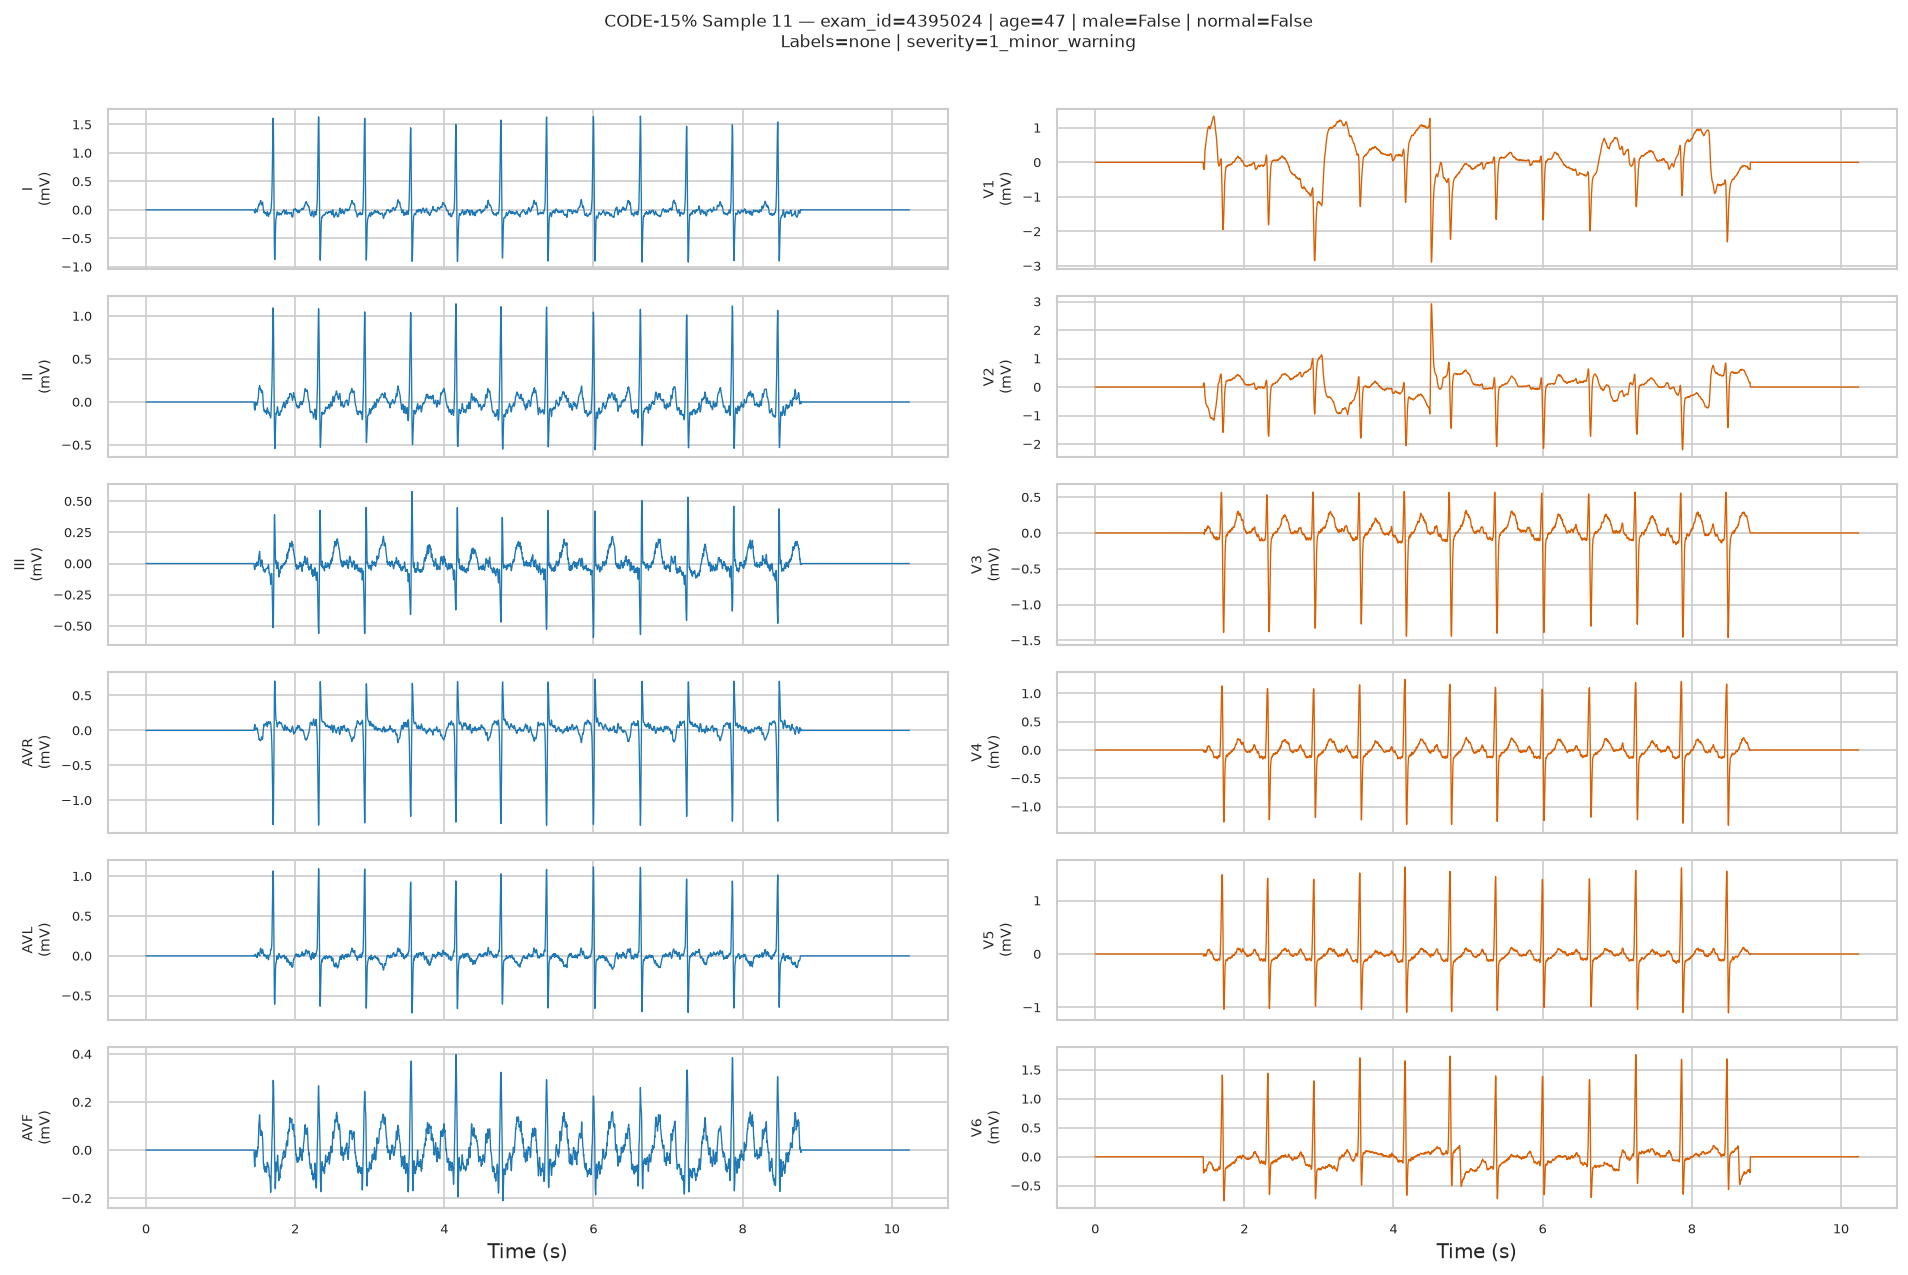

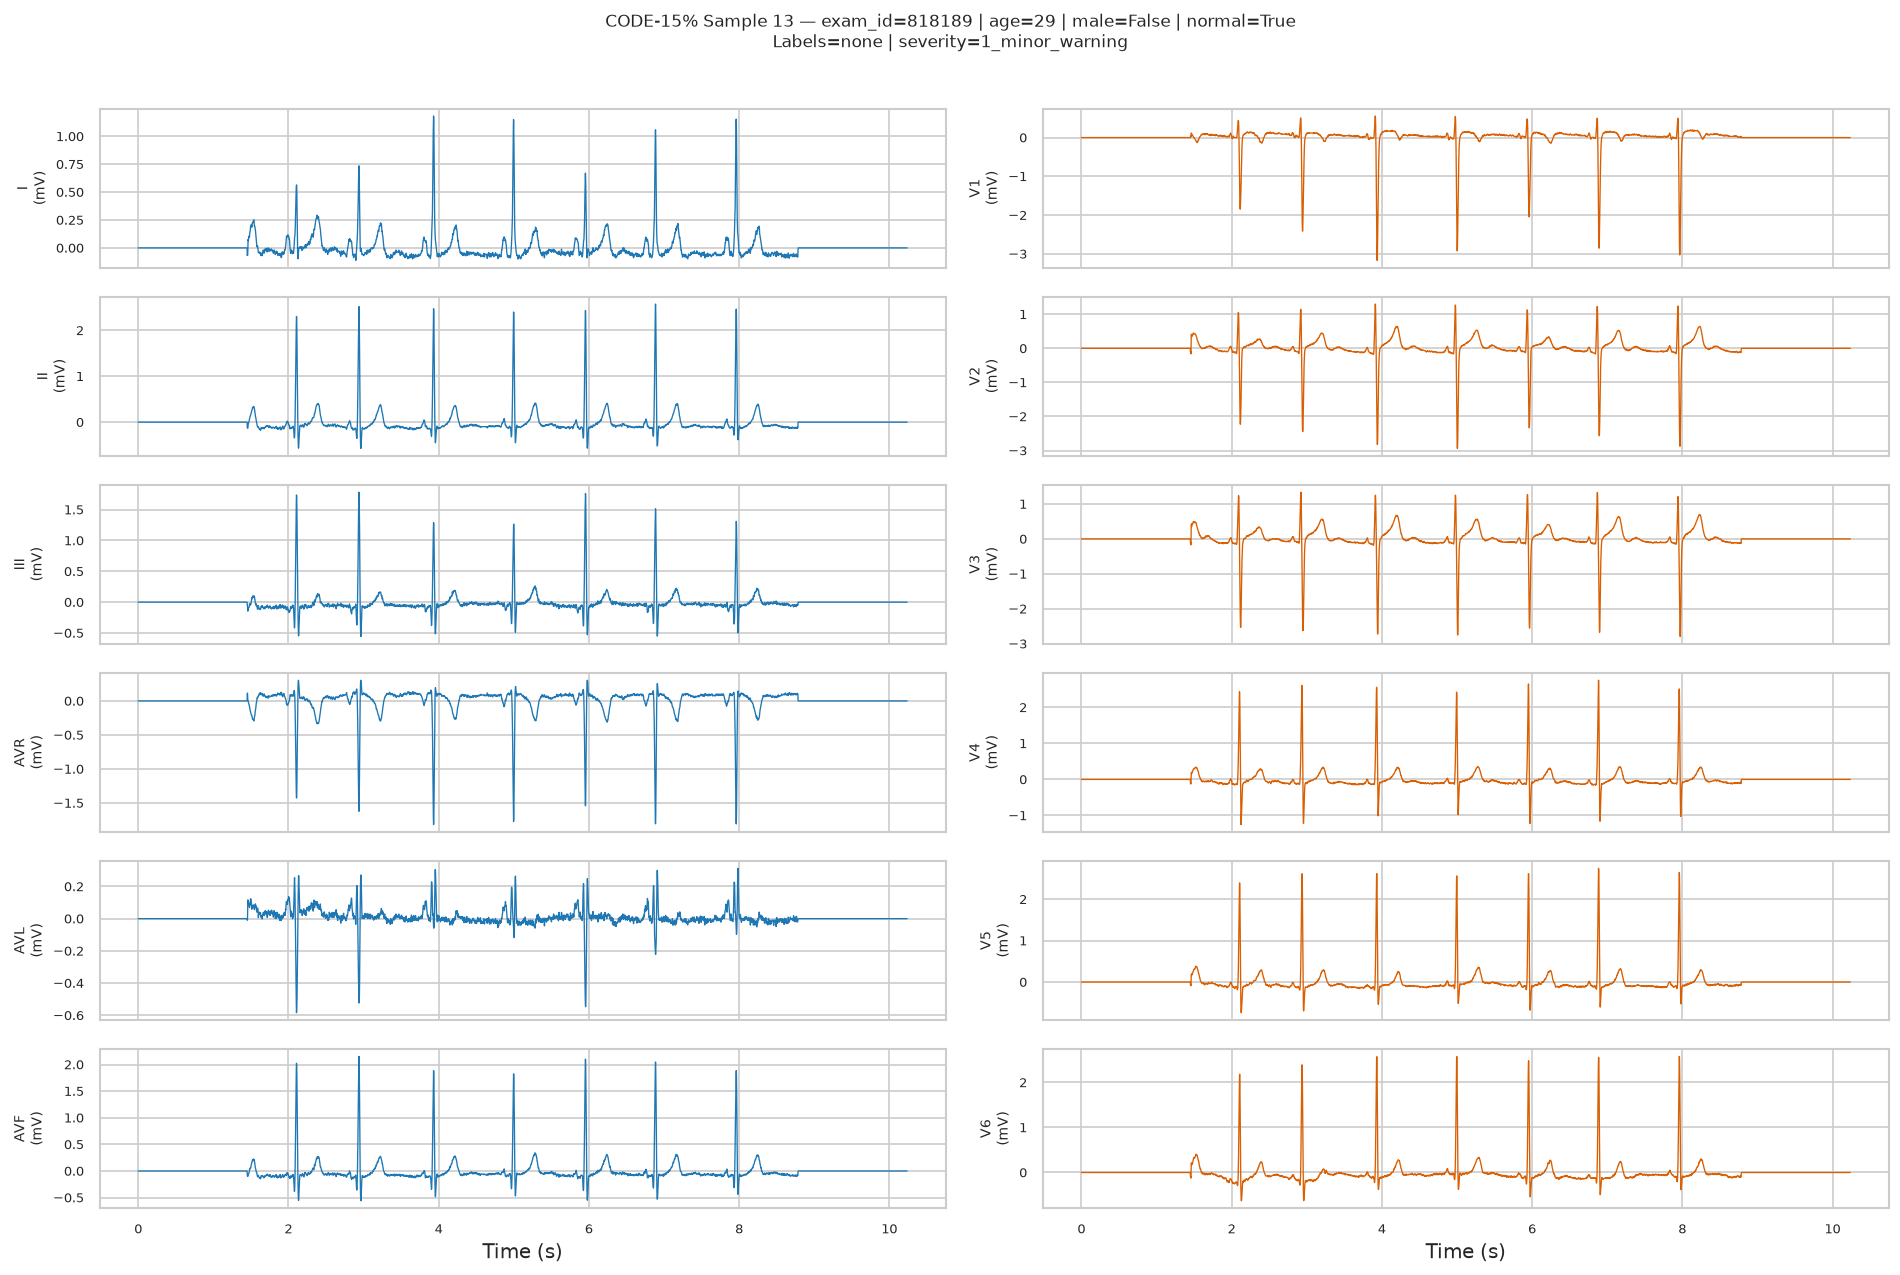

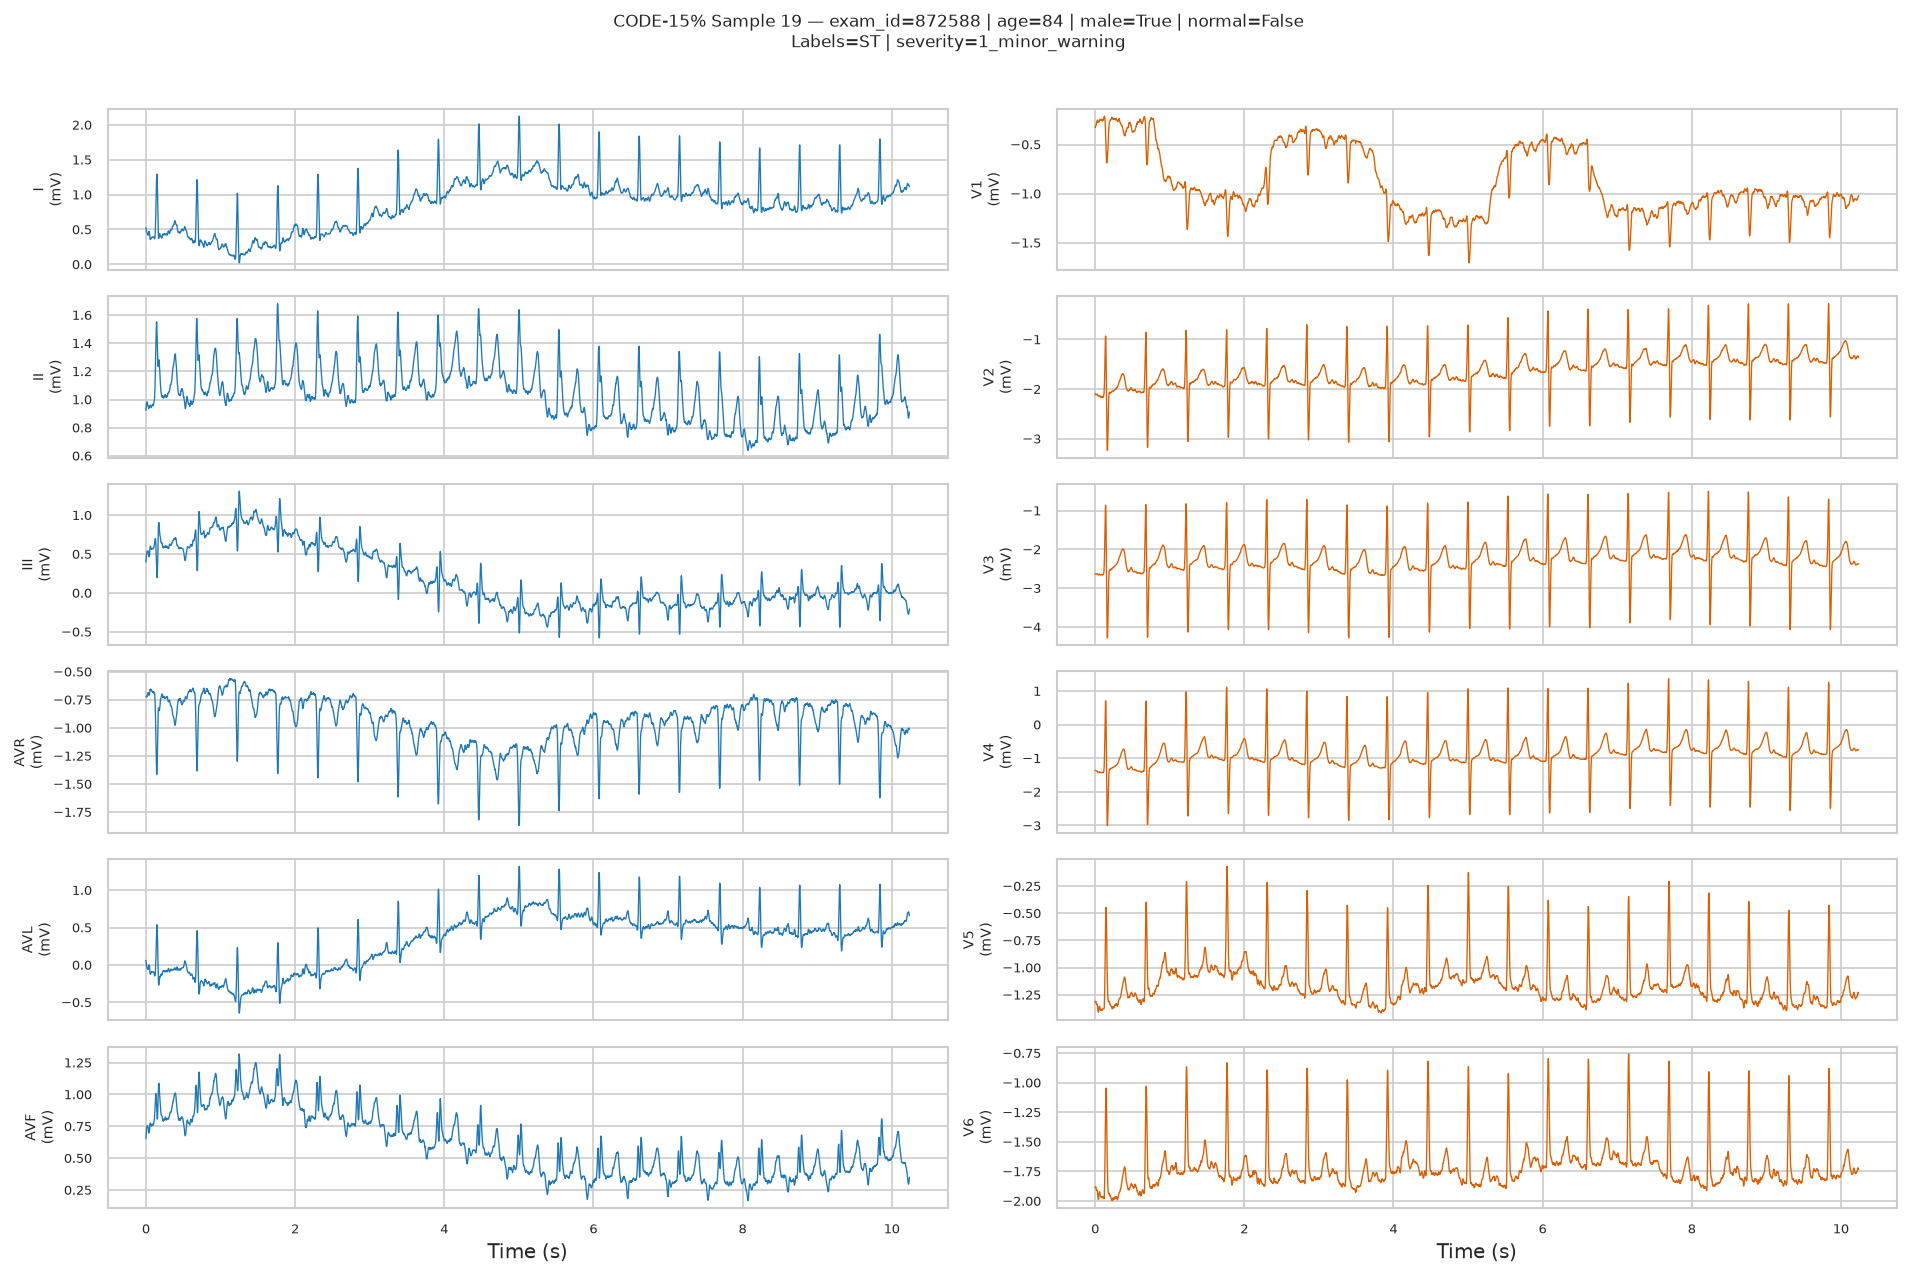

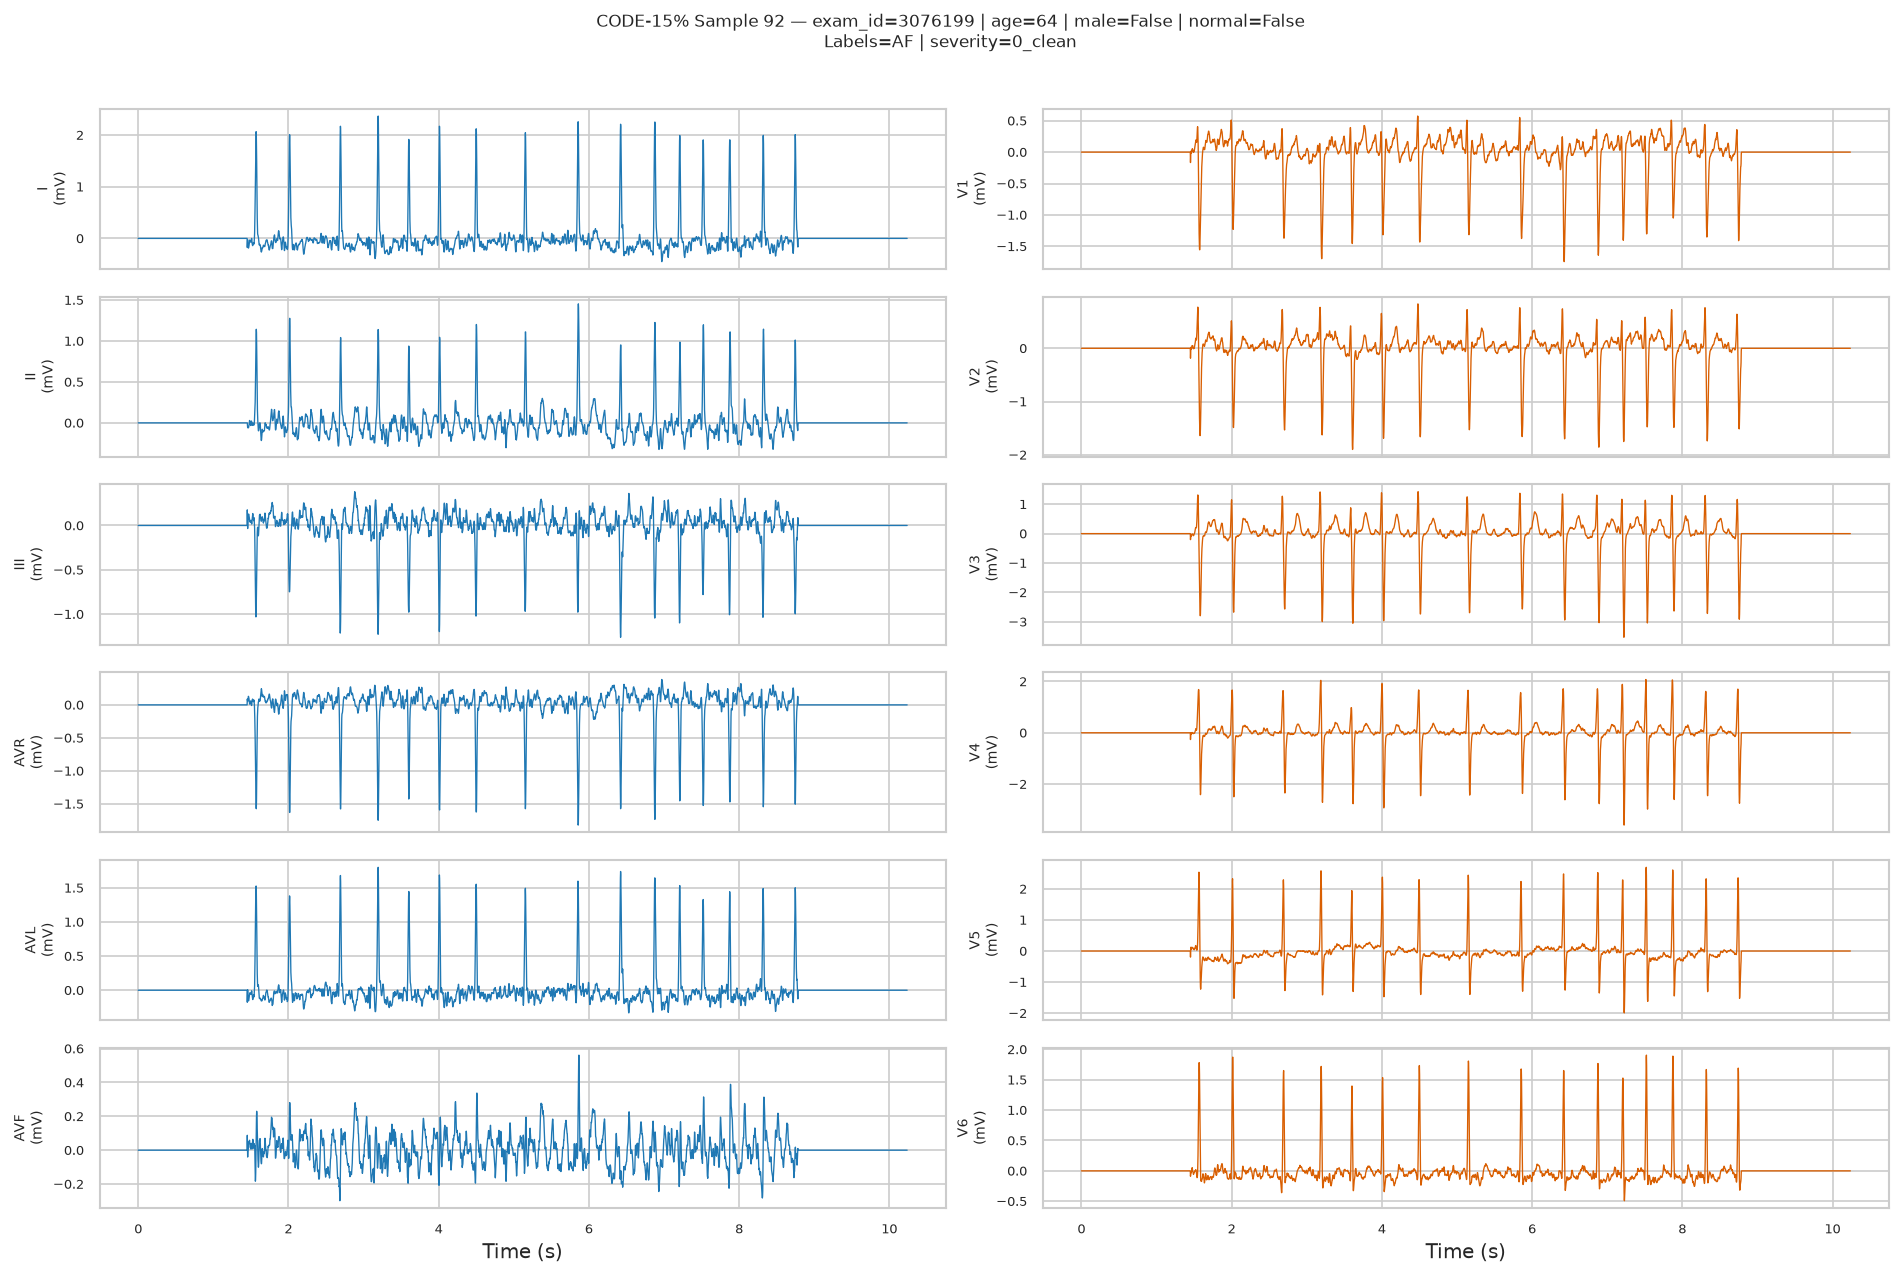

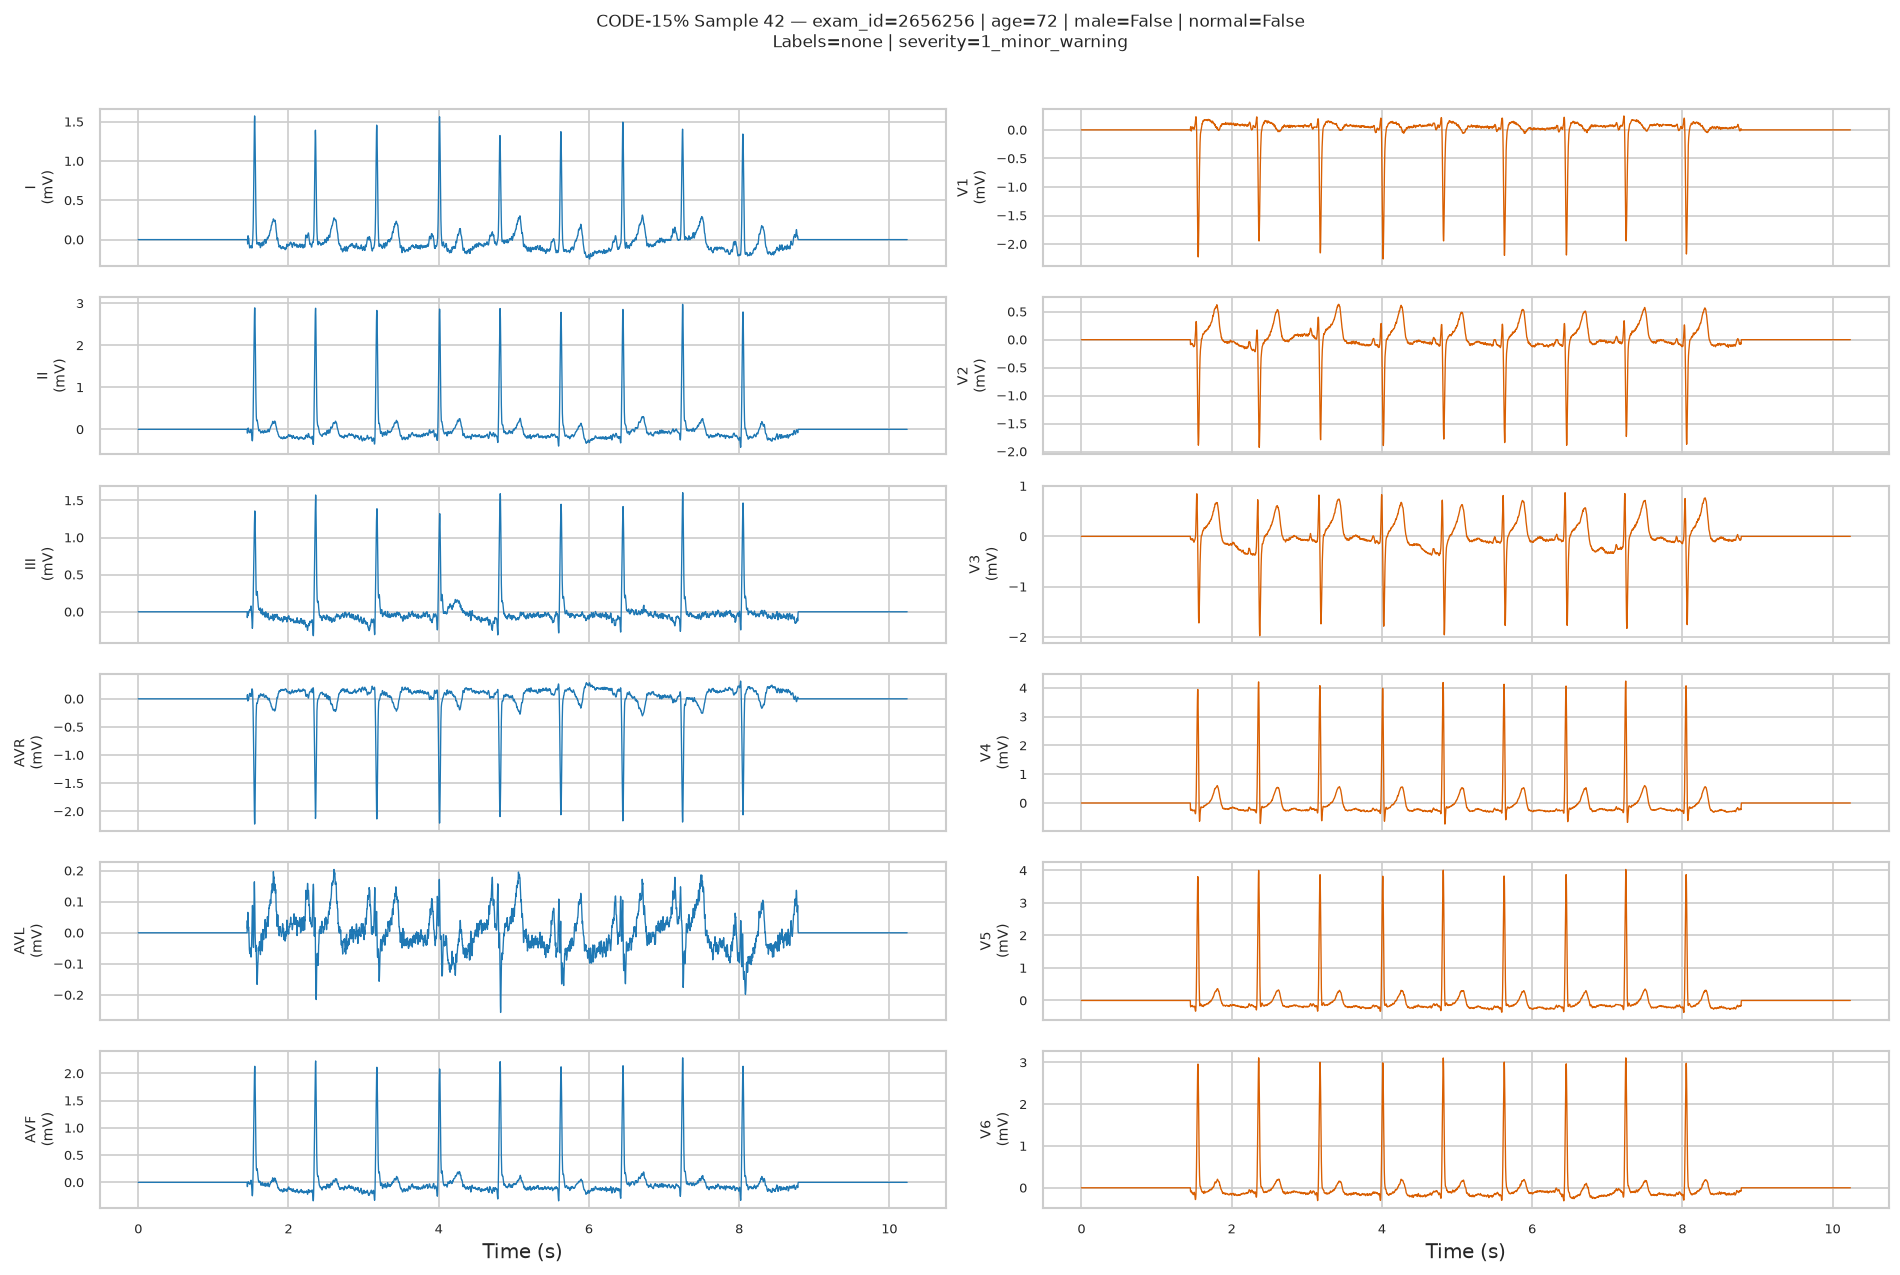

In [2]:
t_full = np.arange(4096) / 400.0

for idx in SAMPLE_INDICES:
    sig = signals[idx]
    row = meta_df.loc[idx]
    fig, axes = plt.subplots(6, 2, figsize=(16, 10.5), sharex=True)
    for j, lname in enumerate(LEADS):
        ax = axes[j % 6, j // 6]
        ax.plot(t_full, sig[:, j], color="#1f78b4" if j < 6 else "#d95f02", lw=0.8)
        ax.set_ylabel(f"{lname}\n(mV)", fontsize=8.5)
        ax.tick_params(labelsize=7.5)
    axes[5, 0].set_xlabel("Time (s)")
    axes[5, 1].set_xlabel("Time (s)")
    fig.suptitle(
        f"CODE-15% Sample {idx} — exam_id={row['exam_id']} | age={row['age']} | male={row['is_male']} | normal={row['normal_ecg']}\n"
        f"Labels={row['active_labels']} | severity={row['severity_tier']}",
        y=1.01, fontsize=10.2,
    )
    plt.tight_layout()
    plt.show()

## 2. Side-by-Side Lineplot Comparison (`0–5 s` Zoom: Lead II & Lead V2)

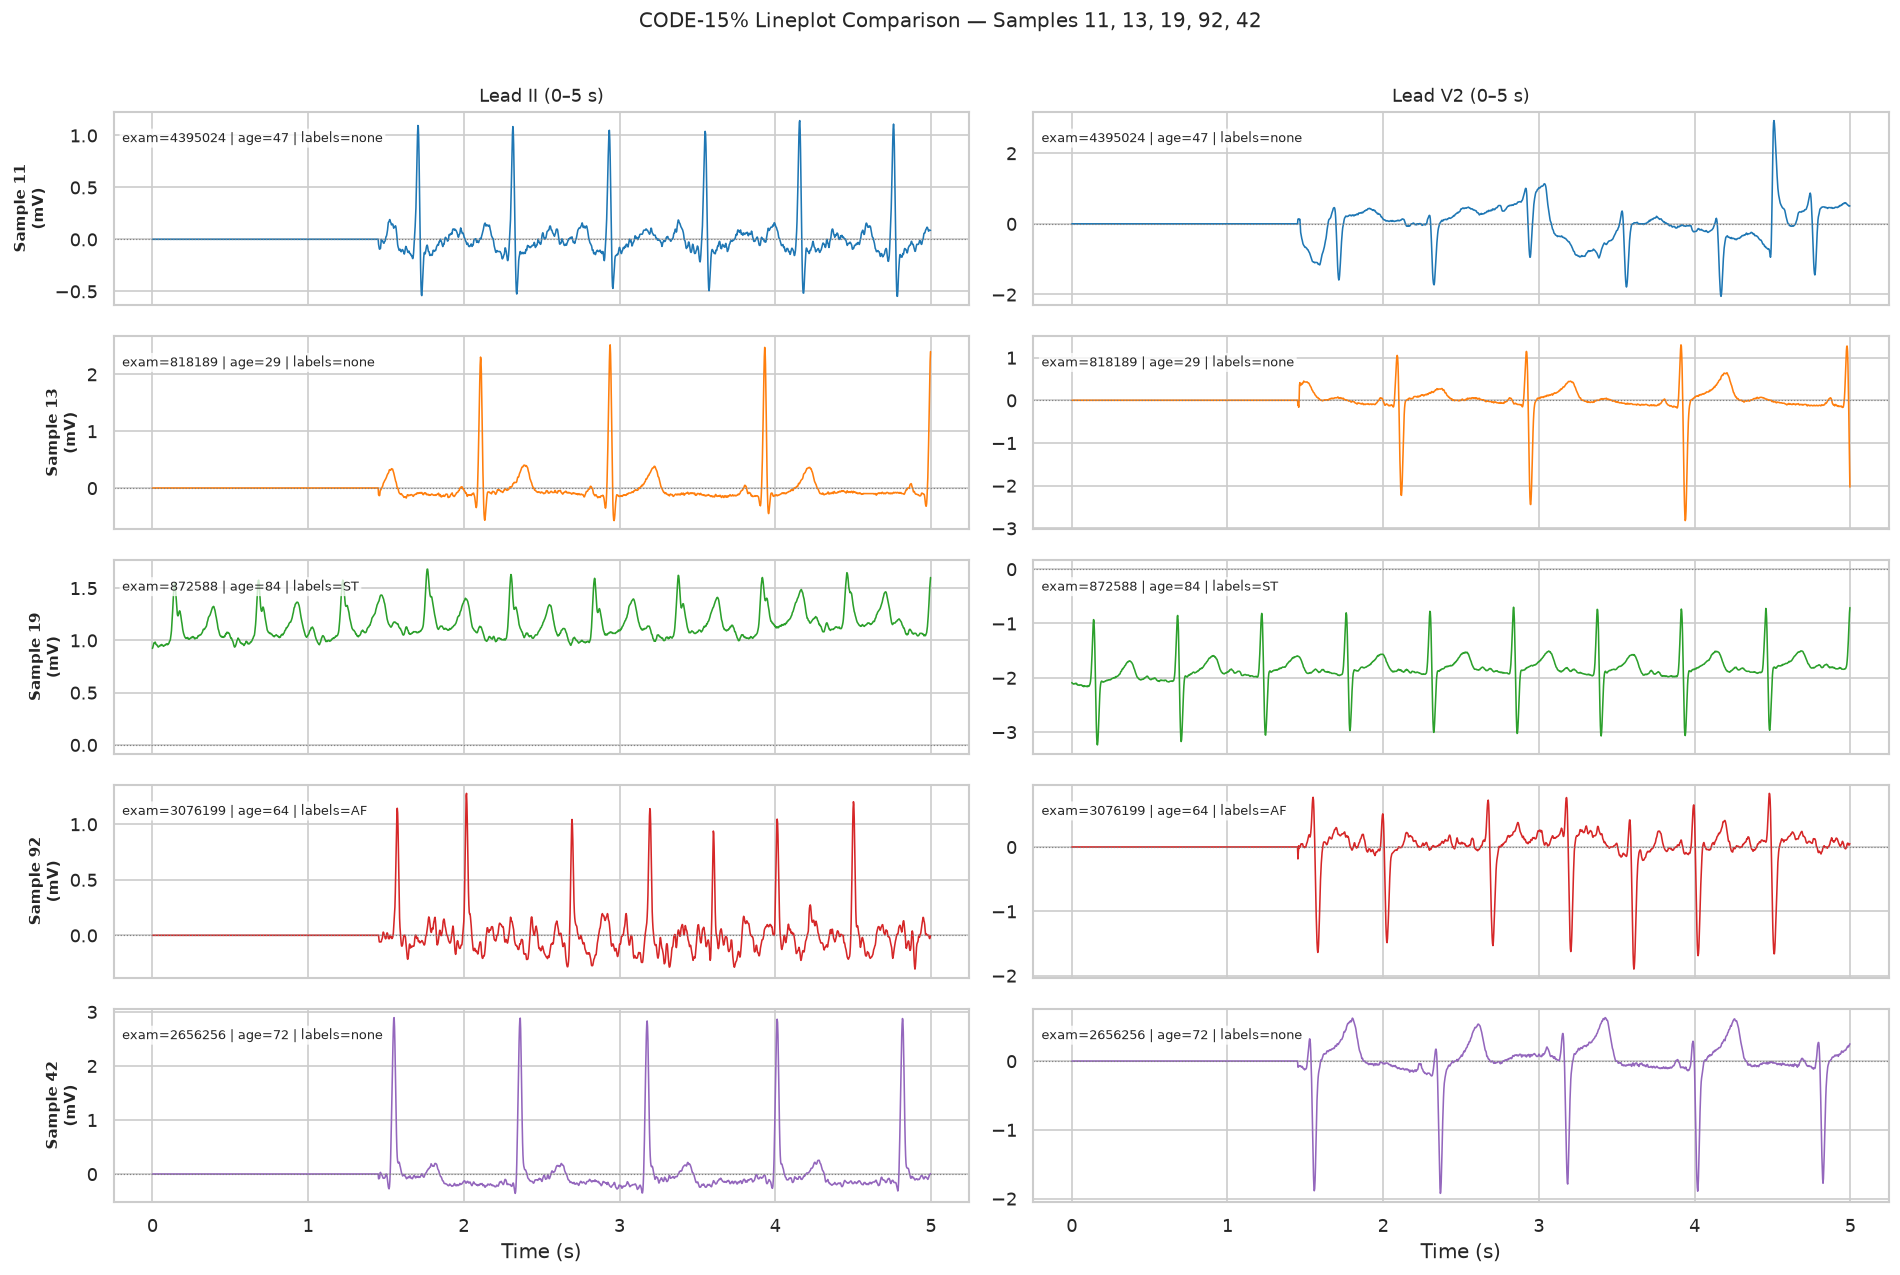

In [3]:
T_ZOOM = 2000  # 5.0 seconds @ 400 Hz
t_zoom = np.arange(T_ZOOM) / 400.0
colors = sns.color_palette("tab10", n_colors=len(SAMPLE_INDICES))

fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(16, 10.5), sharex=True)
for r_i, (idx, col) in enumerate(zip(SAMPLE_INDICES, colors)):
    sig = signals[idx]
    row = meta_df.loc[idx]
    for c_i, (l_idx, lname) in enumerate([(1, "II"), (7, "V2")]):
        ax = axes[r_i, c_i]
        ax.plot(t_zoom, sig[:T_ZOOM, l_idx], color=col, lw=0.95)
        ax.axhline(0, color="gray", ls=":", lw=0.7)
        if c_i == 0:
            ax.set_ylabel(f"Sample {idx}\n(mV)", fontsize=9, fontweight="bold")
        if r_i == 0:
            ax.set_title(f"Lead {lname} (0–5 s)", fontsize=10.5)
        ax.text(
            0.01, 0.90,
            f"exam={row['exam_id']} | age={row['age']} | labels={row['active_labels']}",
            transform=ax.transAxes, fontsize=7.5, va="top",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.78, edgecolor="none"),
        )

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle("CODE-15% Lineplot Comparison — Samples 11, 13, 19, 92, 42", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()